# 1. Análise exploratória das bases

**Projeto:** Agente Identificador de Fraudes Bancárias  
**Disciplina:** Inteligência Artificial – 7º semestre – Ciência da Computação  
**Instituição:** Universidade Presbiteriana Mackenzie – Faculdade de Computação e Informática  
**Professor:** Prof. Dr. Ivan Carlos Alcântara de Oliveira

| Integrante | RA | E-mail |
|---|---|---|
| Cheuk Ki Yu | 10419664 | cheuk.yu@mackenzista.com.br |
| Gabriela Nellessen de Sousa | 10441930 | gabrielanellessen@gmail.com |
| Milton Almeida Leoncio | 10416764 | milton.almeida@live.com |

**Síntese:** Resumo das duas bases, divisão temporal, qualidade dos dados, padrões de fraude por hora, canal das fraudes por ano (mudança de conceito na Base A), valores e categorias.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-10-28 | Milton Almeida Leoncio | Versão inicial da etapa nos resultados preliminares (N1) |
| 2026-11-20 | Milton Almeida Leoncio | Versão final do projeto (N2) |

In [1]:
# ========================================================================================
# Projeto: Agente Identificador de Fraudes Bancárias
# Disciplina: Inteligência Artificial - 7º semestre - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática (FCI)
# Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrantes:
#   Cheuk Ki Yu                  - RA 10419664 - cheuk.yu@mackenzista.com.br
#   Gabriela Nellessen de Sousa  - RA 10441930 - gabrielanellessen@gmail.com
#   Milton Almeida Leoncio       - RA 10416764 - milton.almeida@live.com
# Arquivo: notebooks/01_analise_exploratoria.ipynb
# Síntese: Resumo das duas bases, divisão temporal, qualidade dos dados, padrões de fraude por hora, canal das fraudes por ano (mudança de conceito na Base A), valores e categorias.
# Histórico de alterações:
#   2026-10-28 - Milton Almeida Leoncio - Versão inicial da etapa nos resultados preliminares (N1)
#   2026-11-20 - Milton Almeida Leoncio - Versão final do projeto (N2)
# ========================================================================================

import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
os.environ.setdefault('FRAUDES_ATRIBUTOS', str(RAIZ / 'atributos'))  # saída de preparar_bases.py
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = RAIZ / 'resultados'

## 1.1 Resumo e divisão temporal
As duas bases são públicas e sintéticas. A divisão é temporal: o modelo aprende com o passado e é avaliado no período seguinte, como em um sistema antifraude real.

In [2]:
import eda
eda.resumo()

,Base A - IBM,Base B - Sparkov
Transações (após preparação),24050400,339607
Fraudes,29757,1782
% de fraudes,0.124,0.525
Início,1991-01-02,2019-01-01
Fim,2019-12-31,2020-12-31
Titulares,1657,187
treino: transações,3011396,243168
treino: fraudes,2036,1408
treino: período,01/2017 a 09/2018,01/2019 a 06/2020
validacao: transações,433579,44882


## 1.2 Qualidade dos dados
Contagem de valores ausentes, linhas duplicadas e estornos (valores negativos) nas linhas usadas pelos modelos.

In [3]:
eda.qualidade()

,base,linhas,atributos,valores ausentes,linhas duplicadas,valores negativos (estornos)
0,Base A - IBM,5168913,43,0,0,248979
1,Base B - Sparkov,339607,14,0,0,0


## 1.3 Padrões de fraude

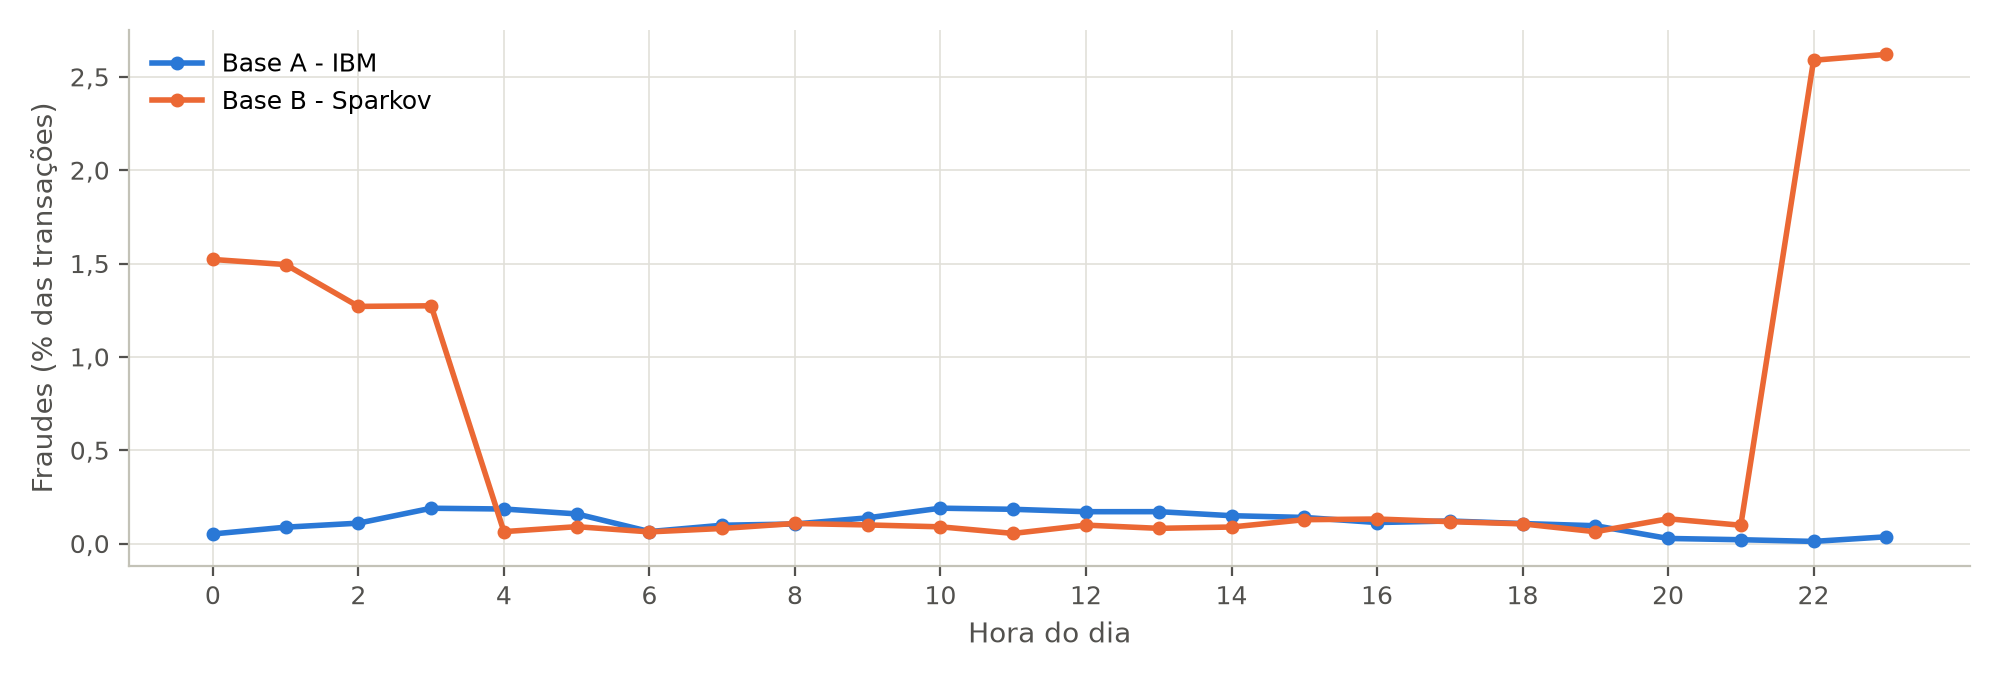

In [4]:
canal = eda.figuras()
display(Image(FIG / 'fig_eda_fraude_por_hora.png', width=900))

Na Base B, as fraudes se concentram entre 22h e 3h. Na Base A, a taxa é baixa e quase uniforme ao longo do dia. O gráfico abaixo mostra o canal das fraudes por ano na Base A: até 2016 a maioria era online; a partir de 2017 quase todas são compras no exterior. Essa mudança de conceito orientou a divisão temporal e o Experimento 4.

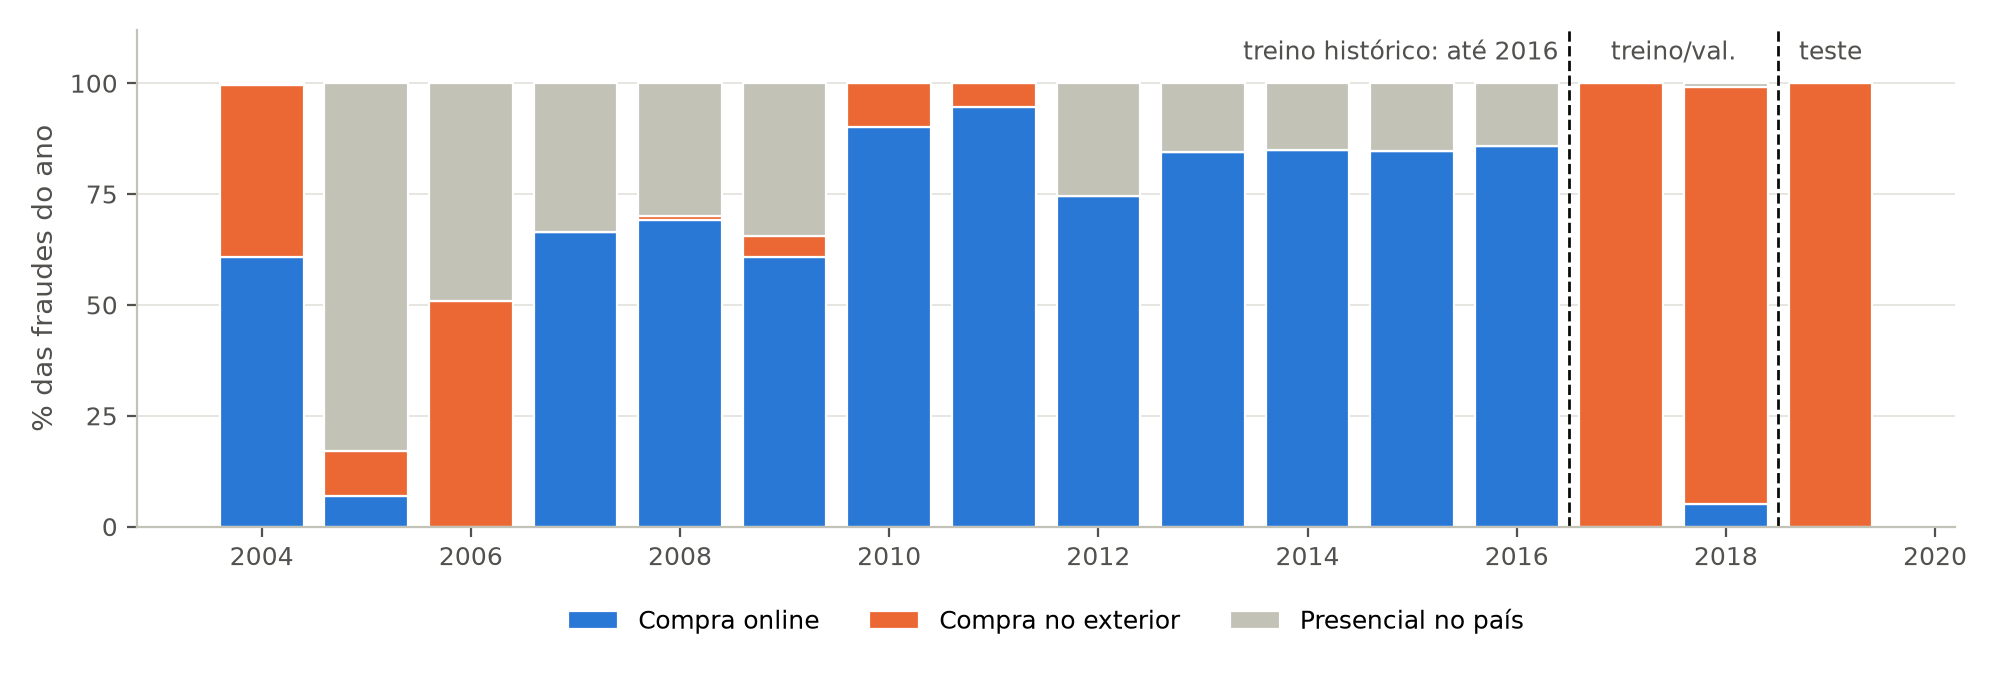

,online,exterior,fraudes
ano,,,
2010,0.902,0.098,3835
2011,0.945,0.055,55
2012,0.745,0.000,1333
2013,0.845,0.000,2018
2014,0.849,0.000,1052
2015,0.846,0.000,3281
2016,0.859,0.000,3579
2017,0.000,1.000,255
2018,0.051,0.939,2491


In [5]:
display(Image(FIG / 'fig_eda_canal_fraudes_A.png', width=900))
canal.tail(10)

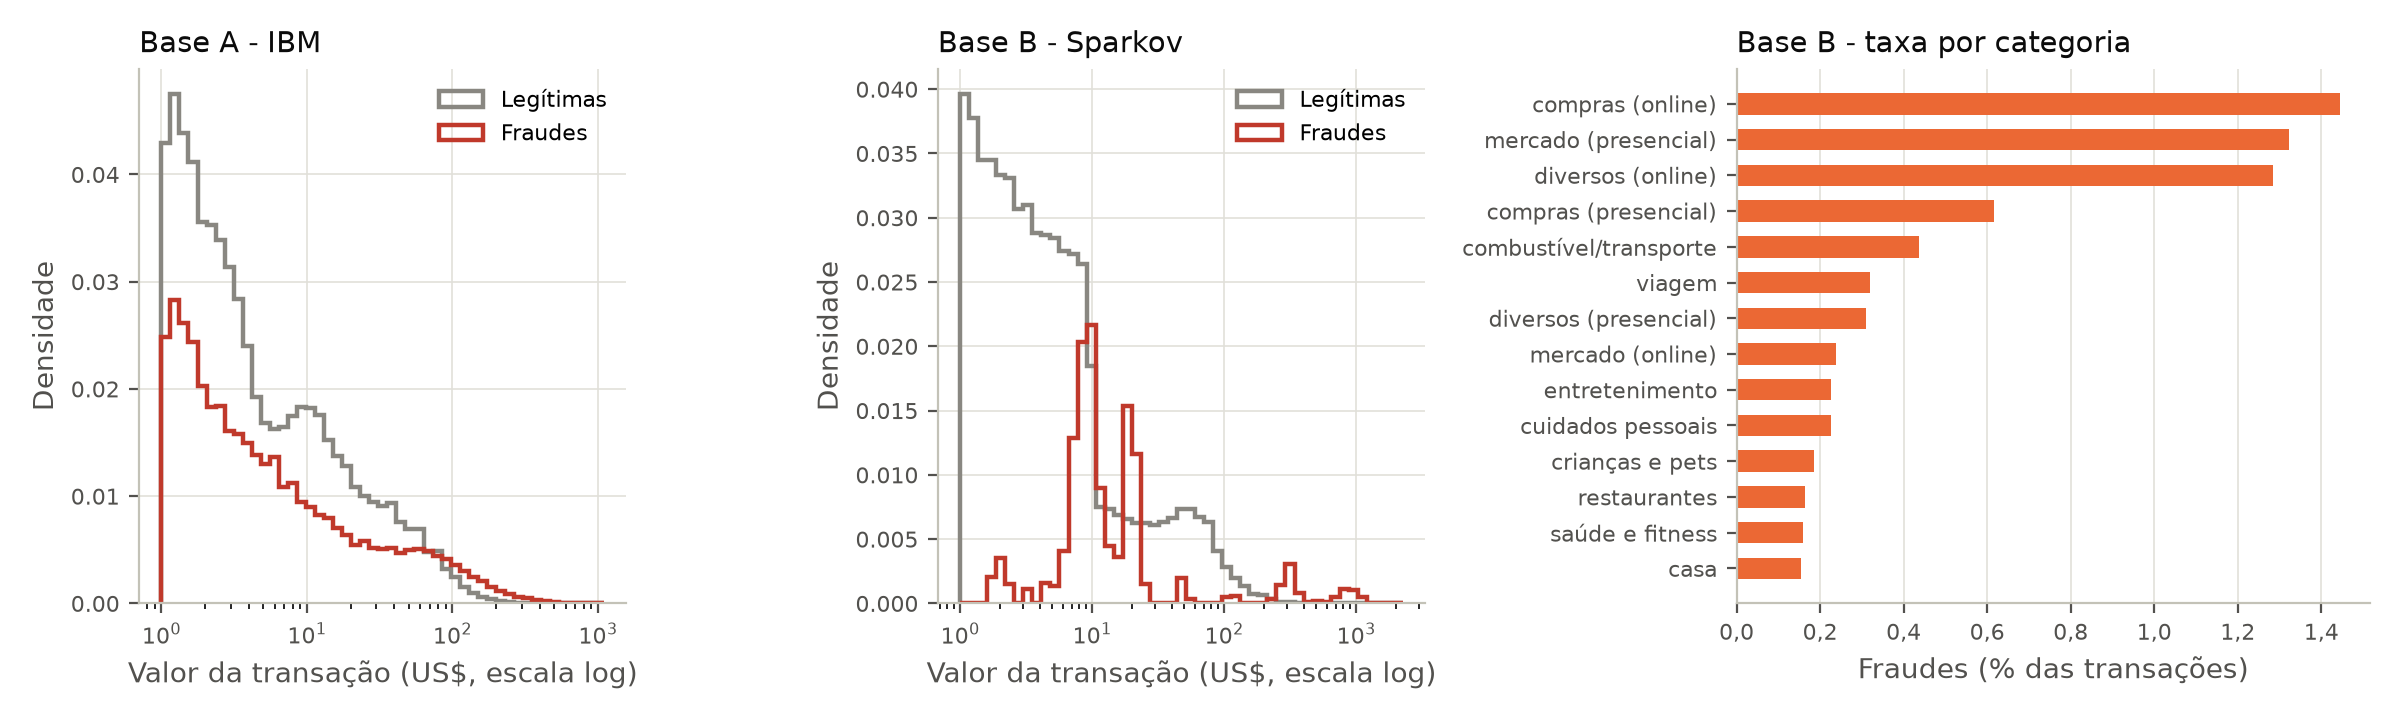

In [6]:
display(Image(FIG / 'fig_eda_valores_categorias.png', width=1000))

## 1.4 Concentração das fraudes por titular
Na Base A, as fraudes acontecem em surtos curtos, concentrados em poucos cartões, e quase nenhum cartão fraudado no teste já tinha sido fraudado no treino. Por isso, atributos que identificam o titular (renda, dívida, limite etc.) não ajudam a prever fraudes futuras (Experimento 1).

In [7]:
eda.concentracao_fraudes()

,base,periodo,fraudes,titulares_ativos,titulares_com_fraude,fraudes_por_titular_mediana,duracao_surto_dias_mediana,titulares_com_fraude_tambem_no_treino
0,Base A - IBM,treino,2036,4072,223,9.000,12.000,NaN
1,Base A - IBM,validacao,710,3909,91,8.000,8.000,19.000
2,Base A - IBM,teste,2087,4029,244,9.000,11.000,11.000
3,Base B - Sparkov,treino,1408,183,143,10.000,1.000,NaN
4,Base B - Sparkov,validacao,203,170,24,9.000,1.000,1.000
5,Base B - Sparkov,teste,171,172,16,9.500,1.000,0.000
